In [111]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from numpy import empty, array, arange
from pylab import plot, show

base_dir = Path("solutions4.ipynb").resolve().parent
figures_dir = base_dir / "figures"
figures_dir.mkdir(exist_ok="True")

In [112]:
plt.style.use("classic")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "monospace",
    "font.monospace": ["DejaVu Sans Mono"],
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.linewidth": 2.0,
    "axes.grid": False,
    "lines.color": "black",
    "lines.linewidth": 2.5,
    "xtick.color": "black",
    "ytick.color": "black",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
})

Accepted intervals: 37
x(20) = 0.3751036101560969
y(20) = 3.727915836006738


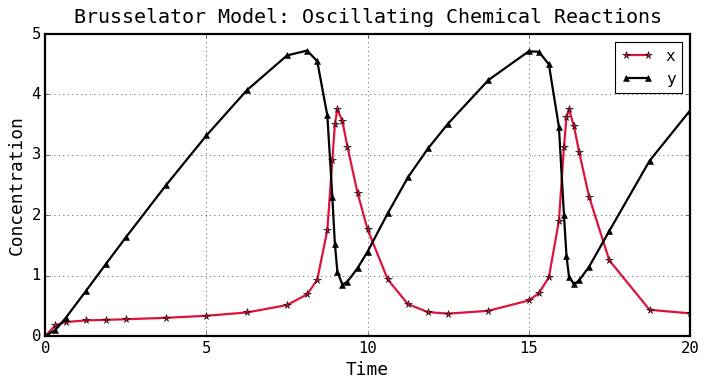

In [113]:
# 8.18 Oscillating Chemical Reactions - Belousov-Zhabotinsky Reaction
# using the adaptive Bulirsch-Stoer method recursively

from functools import lru_cache

a = 1
b = 3
x0 = 0
y0 = 0
delta = 1e-10  # accuracy per unit time in both x and y
ti = 0
tf = 20
H = 20  # initially using a single time interval
n = 8   # maximum modified midpoint steps before dividing in half

def f(t, state): # brusselator model
    x, y = state
    dxdt = 1 - (b+1)*x + a* x**2 *y
    dydt = b*x - a*x**2*y
    return np.array([dxdt, dydt])

def modified_midpoint(t, state, H, steps):
    h = H / steps
    y = state + 0.5 * h * f(t, state)
    x = state + h * f(t + 0.5 * h, y)
    for i in range(steps - 1):
        y = y + h * f(t + (i + 1)*h, x)
        x = x + h * f(t + (i + 1.5)*h, y)
    return 0.5*(x + y + 0.5*h*f(t + H, x))

times = [ti] # now we store the solution at each interval boundary that's accepted
solutions = [np.array([x0, y0], dtype=float)]

def bulirsch_stoer(t, state, H, depth=0): # starting with full H=20 since depth=0 by default
    if depth > 30:
        raise RuntimeError("Too many interval subdivisions")
    @lru_cache(None)
    def R(n, m): # Richardson extrapolation
        if m == 1:
            return modified_midpoint(t, state, H, n)
        lower = R(n, m-1)
        previous = R(n-1, m-1)
        factor = (n/(n - m + 1))**2 - 1
        return lower + (lower - previous)/factor
    with np.errstate(over="ignore", invalid="ignore"):
        for steps in range(2, n + 1):
            estimate = R(steps, steps)
            error = np.abs(estimate - R(steps, steps - 1))
            if (np.all(np.isfinite(estimate))
                    and np.all(error <= delta*H)):
                times.append(t + H)
                solutions.append(estimate.copy())
                return estimate
    # if n = 8 isn't enough, we divide the interval in half
    middle = bulirsch_stoer(t, state, H/2, depth + 1)
    return bulirsch_stoer(t + H/2, middle, H/2, depth + 1)

bulirsch_stoer(ti, solutions[0], H)
times = np.array(times)
solutions = np.array(solutions)
print(f"Accepted intervals: {len(times)-1}")
print(f"x(20) = {solutions[-1,0]}")
print(f"y(20) = {solutions[-1,1]}")

fig = plt.figure(figsize=(9, 5))
plt.plot(times, solutions[:, 0], color="crimson", linewidth=2, marker="*", markersize=7, label="x")
plt.plot(times, solutions[:, 1], color="black", linewidth=2, marker="^", markersize=5, label="y")
plt.xlabel("Time")
plt.ylabel("Concentration")
plt.grid(True)
plt.legend()
plt.title("Brusselator Model: Oscillating Chemical Reactions", pad=10)
plt.tight_layout()
plt.show()
fig.savefig(figures_dir / "brusselator.png", dpi=300)

In [114]:
# Fourth-Order Runge-Kutta Method for Supermassive Black Hole Binary

from numba import njit

@njit
def eom(t, state, A, B):
    x, y, vx, vy = state
    r = np.sqrt(x**2 + y**2)
    v = np.sqrt(vx**2 + vy**2)
    ax_gravity = -x / (4 * r**3)
    ay_gravity = -y / (4 * r**3)
    ax_df = -(A * vx) / (v**3 + B)
    ay_df = -(A * vy) / (v**3 + B)
    return np.array([vx, vy, ax_gravity + ax_df, ay_gravity + ay_df])

@njit
def rk4(t, state, h, A, B):
    k1 = h * eom(t, state, A, B)
    k2 = h * eom(t + 0.5*h, state + 0.5*k1, A, B)
    k3 = h * eom(t + 0.5*h, state + 0.5*k2, A, B)
    k4 = h * eom(t + h, state + k3, A, B)
    return state + (k1 + 2*k2 + 2*k3 + k4)/6

# Adaptive RK4 with step doubling


def adaptive_rk4(initial_state, A, B, delta, t_end, h0=0.01, max_steps=1000000, r_stop=None):
    t = 0.0
    h = h0
    state = initial_state.copy()
    times = [t]
    states = [state.copy()]
    attempts = 0

    while t < t_end:
        if attempts >= max_steps:
            raise RuntimeError("Maximum number of steps exceeded")

        h = min(h, (t_end-t)/2)

        if t + 2*h == t:
            raise RuntimeError("Time step too small")

        # one large step of size 2h
        large = rk4(t, state, 2*h, A, B)

        # two small steps of size h
        half = rk4(t, state, h, A, B)
        small = rk4(t+h, half, h, A, B)
        attempts += 1

        error = np.linalg.norm(large[:2] - small[:2])

        # ratio of target accuracy to estimated error
        if not np.isfinite(error) or not np.all(np.isfinite(small)):
            rho = 0.0
        else:
            rho = np.inf if error == 0 else 30*h*delta/error

        # accepting step if accuracy is enough
        if rho >= 1:
            if r_stop is not None:
                r_half = np.hypot(half[0], half[1])
                r_small = np.hypot(small[0], small[1])
                if r_half <= r_stop or r_small <= r_stop:
                    if r_half <= r_stop:
                        left_t = t
                        left_state = state.copy()
                    else:
                        left_t = t + h
                        left_state = half.copy()
                    lo, hi = 0.0, h
                    for _ in range(40):
                        mid = (lo + hi)/2
                        mid_state = rk4(left_t, left_state, mid, A, B)
                        if np.hypot(mid_state[0], mid_state[1]) <= r_stop:
                            hi = mid
                        else:
                            lo = mid
                    t = left_t + hi
                    state = rk4(left_t, left_state, hi, A, B)
                    times.append(t)
                    states.append(state.copy())
                    break

            t += 2*h
            state = small
            times.append(t)
            states.append(state.copy())

        factor = 2.0 if np.isinf(rho) else np.clip(0.9*rho**0.25, 0.1, 2.0)
        h *= factor
    return np.array(times), np.array(states)


In [115]:
# (a) frictionless orbit

r_peri = 1e-7
r_apo = 1.0

# initial conditions from the vis-viva equation
a = (r_peri + r_apo)/2
v0 = np.sqrt(0.5*r_peri/(r_apo*(r_apo+r_peri)))
T = 2 * np.pi * np.sqrt(4*a**3)
ti = 0
tf = 12*T
state0 = np.array([r_apo, 0.0, 0.0, v0])

@njit
def orbital(states):
    x, y, vx, vy = states.T
    r = np.sqrt(x**2 + y**2)
    E = 0.5*(vx**2 + vy**2) - 1/(4*r)
    L = x*vy - y*vx
    mu = 0.25
    ecc = np.sqrt(np.maximum(0, 1 + 2*E*L**2/mu**2))
    rp = (L**2/mu)/(1 + ecc)
    E_error = np.abs((E-E[0])/E[0])
    L_error = np.abs((L-L[0])/L[0])
    return r, E_error, L_error, rp

results = {}
for delta in [1e-8, 1e-9, 1e-10]:
    times, states = adaptive_rk4(state0, A=0, B=1, delta=delta, t_end=tf)
    results[delta] = (times, states)
    r, E_error, L_error, rp = orbital(states)
    print(f"delta = {delta:.0e}")
    print(f"Max energy error = {max(E_error):.3e}")
    print(f"Max angular momentum error = {max(L_error):.3e}")
    print(f"Max pericenter drift = {max(np.abs(rp/r_peri-1)):.3e}")
    print(f"Number of steps = {len(times)-1}\n")

delta = 1e-10
times, states = results[delta]
r, E_error, L_error, rp = orbital(states)

delta = 1e-08
Max energy error = 4.809e-04
Max angular momentum error = 5.318e-09
Max pericenter drift = 1.066e-08
Number of steps = 28659

delta = 1e-09
Max energy error = 3.595e-05
Max angular momentum error = 2.861e-10
Max pericenter drift = 5.738e-10
Number of steps = 50976

delta = 1e-10
Max energy error = 2.608e-06
Max angular momentum error = 1.779e-11
Max pericenter drift = 3.565e-11
Number of steps = 90651



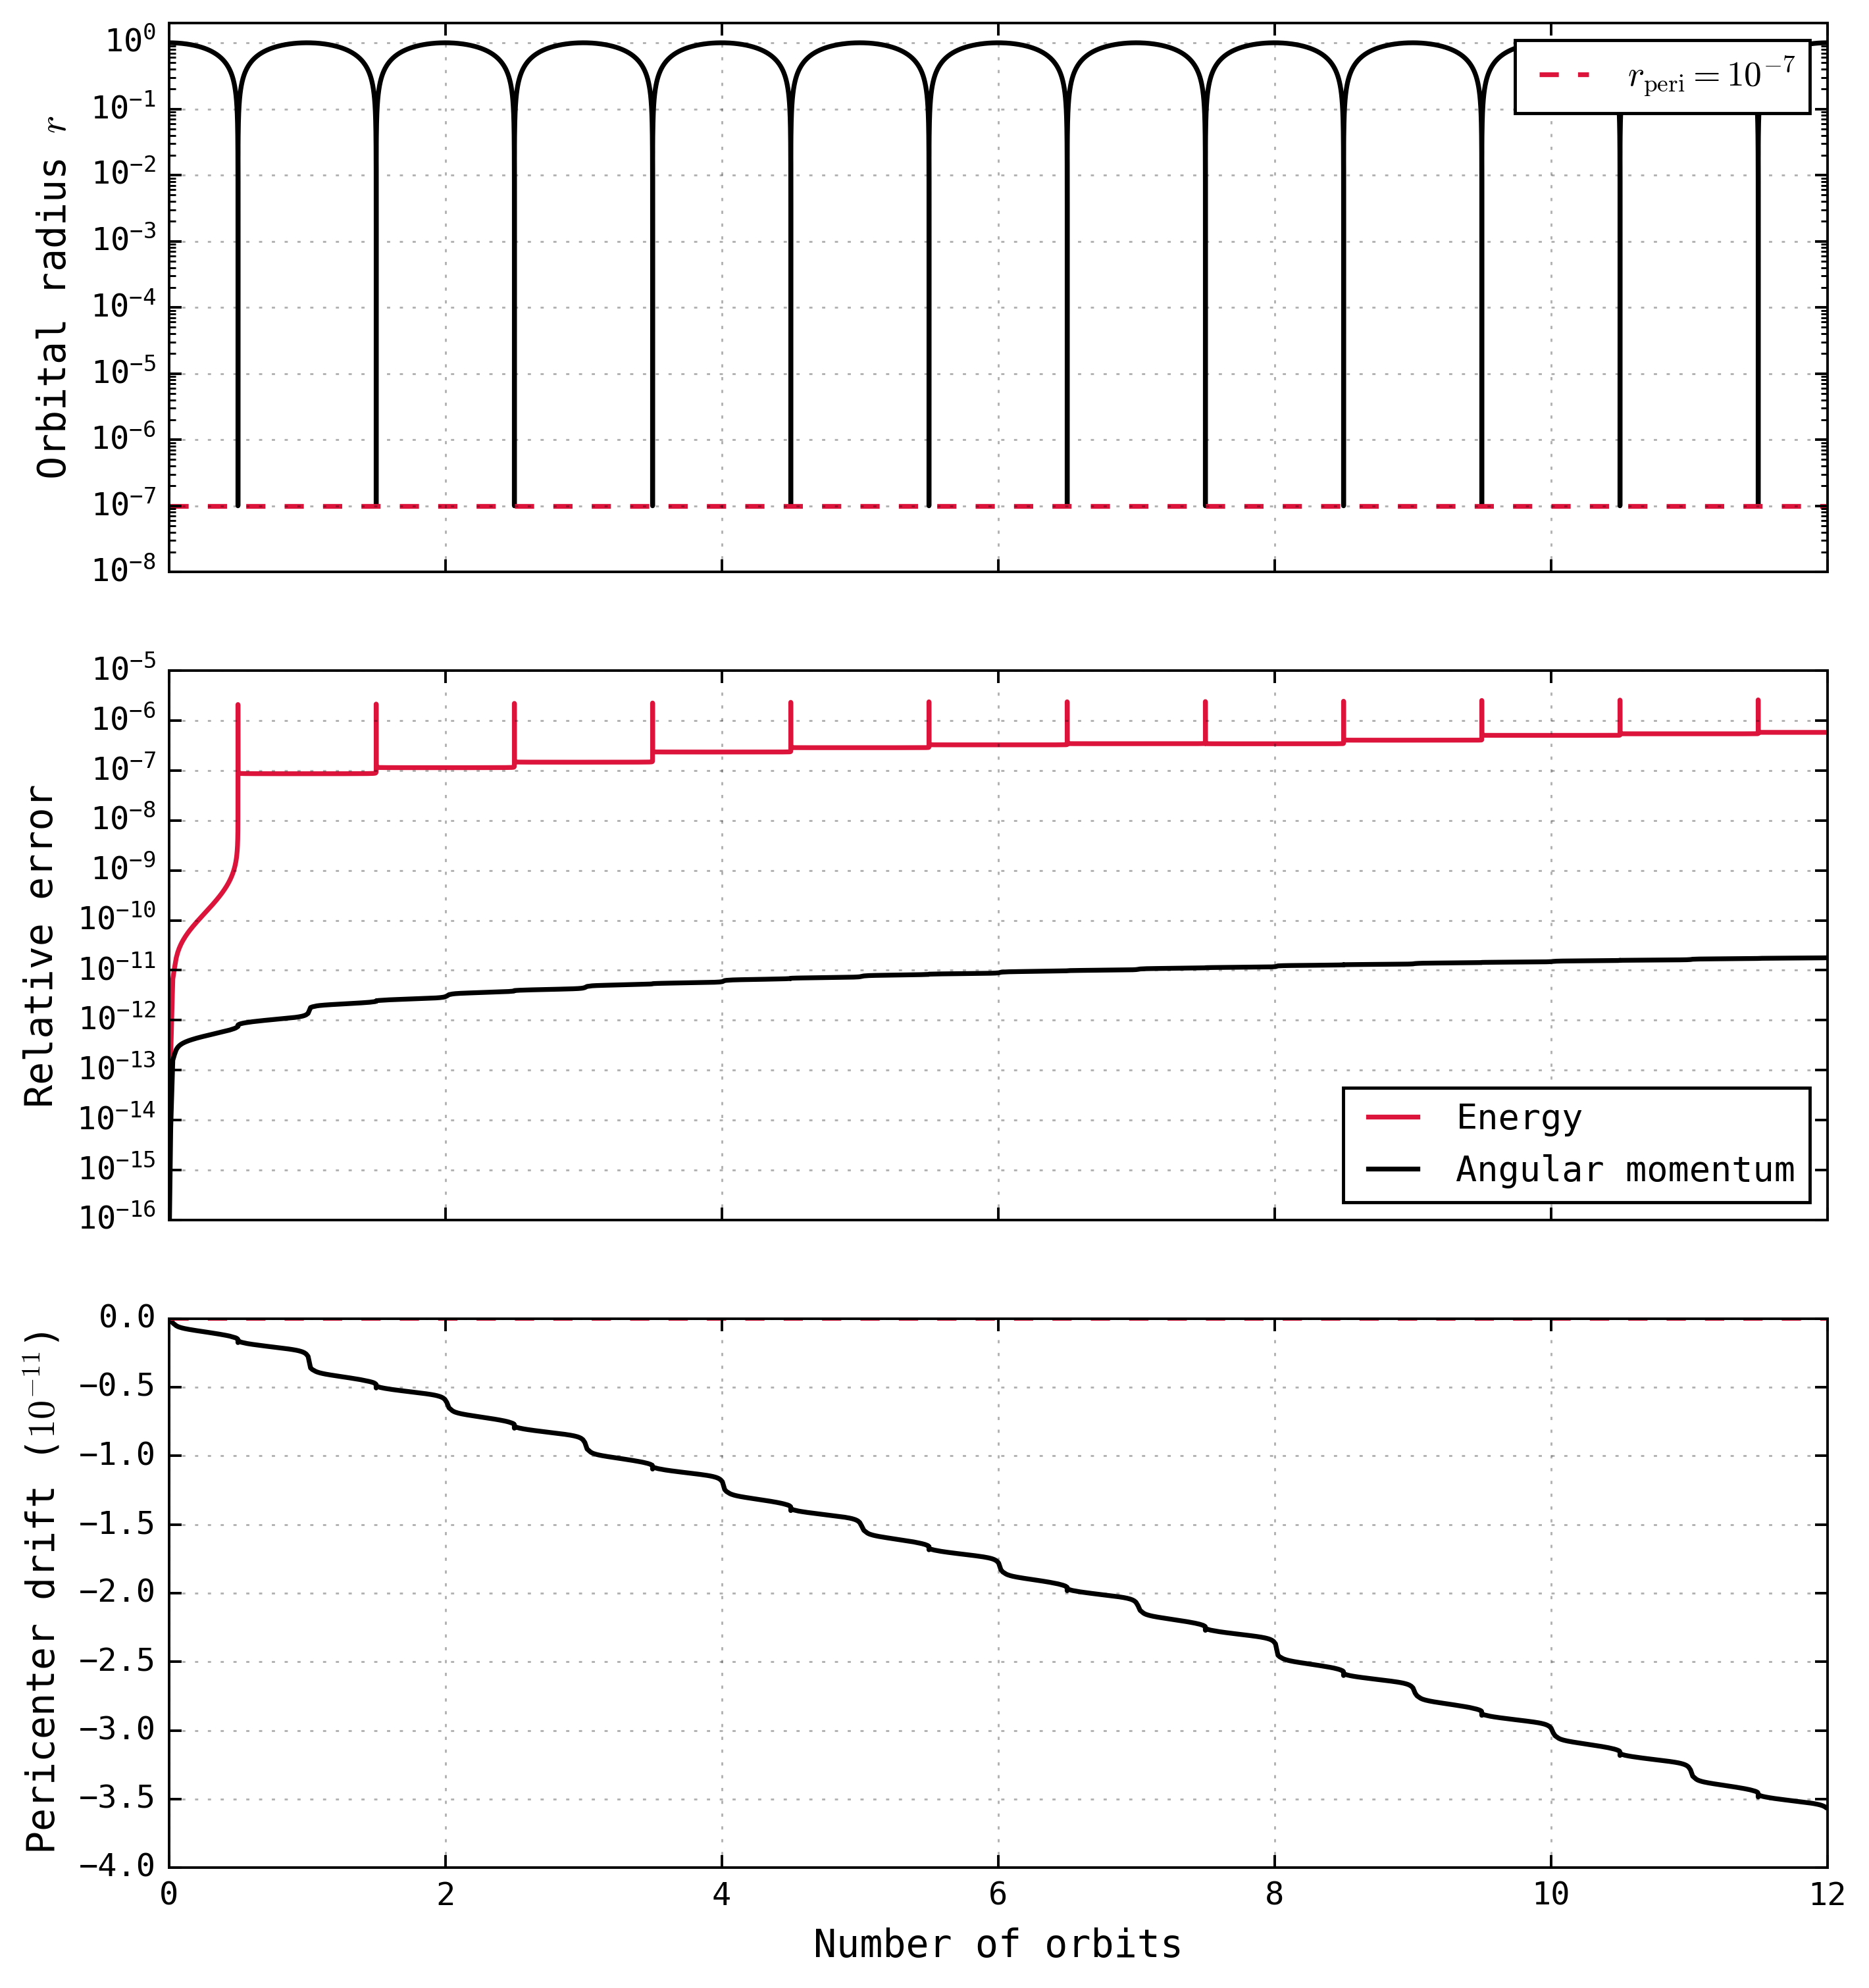

In [116]:

fig, ax = plt.subplots(3, 1, figsize=(9, 9), dpi=350, sharex=True, gridspec_kw={"hspace": 0.18})

ax[0].semilogy(times/T, r, color="black", linewidth=1.5)
ax[0].axhline(r_peri, color="crimson", linestyle="--", linewidth=1.5, label=r"$r_{\mathrm{peri}}=10^{-7}$")
ax[0].set_ylim(1e-8, 2)
ax[0].set_ylabel(r"Orbital radius $r$", fontsize=12)
ax[0].legend(loc="upper right", fontsize=11, frameon=True)

ax[1].semilogy(times/T, np.maximum(E_error, 1e-16), color="crimson", linewidth=1.5, label="Energy")
ax[1].semilogy(times/T, np.maximum(L_error, 1e-16), color="black", linewidth=1.5, label="Angular momentum")
ax[1].set_ylabel("Relative error", fontsize=12)
ax[1].legend(loc="lower right", fontsize=11, frameon=True)

ax[2].plot(times/T, (rp/r_peri - 1)*1e11, color="black", linewidth=1.5)
ax[2].axhline(0, color="crimson", linestyle="--", linewidth=1)
ax[2].set_ylabel(r"Pericenter drift ($10^{-11}$)", fontsize=12)
ax[2].set_xlabel("Number of orbits", fontsize=12)

for axis in ax:
    axis.tick_params(axis="both", direction="in", top=True, right=True, labelsize=10, width=0.8, length=4)
    axis.tick_params(which="minor", direction="in", top=True, right=True, width=0.6, length=2)
    axis.grid(True, which="major", linestyle=":",linewidth=0.6, alpha=0.3)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)

ax[2].set_xlim(0, 12)
ax[2].set_xticks(np.arange(0, 13, 2))

plt.subplots_adjust(left=0.17, right=0.97, top=0.98, bottom=0.09)
plt.savefig(figures_dir / "bh_part_a.png", dpi=350, bbox_inches="tight")
plt.show()


Reached Schwarzschild radius: True
Final radius = 1.000e-07
Final time = 10.755646 code units
Number of steps = 150408


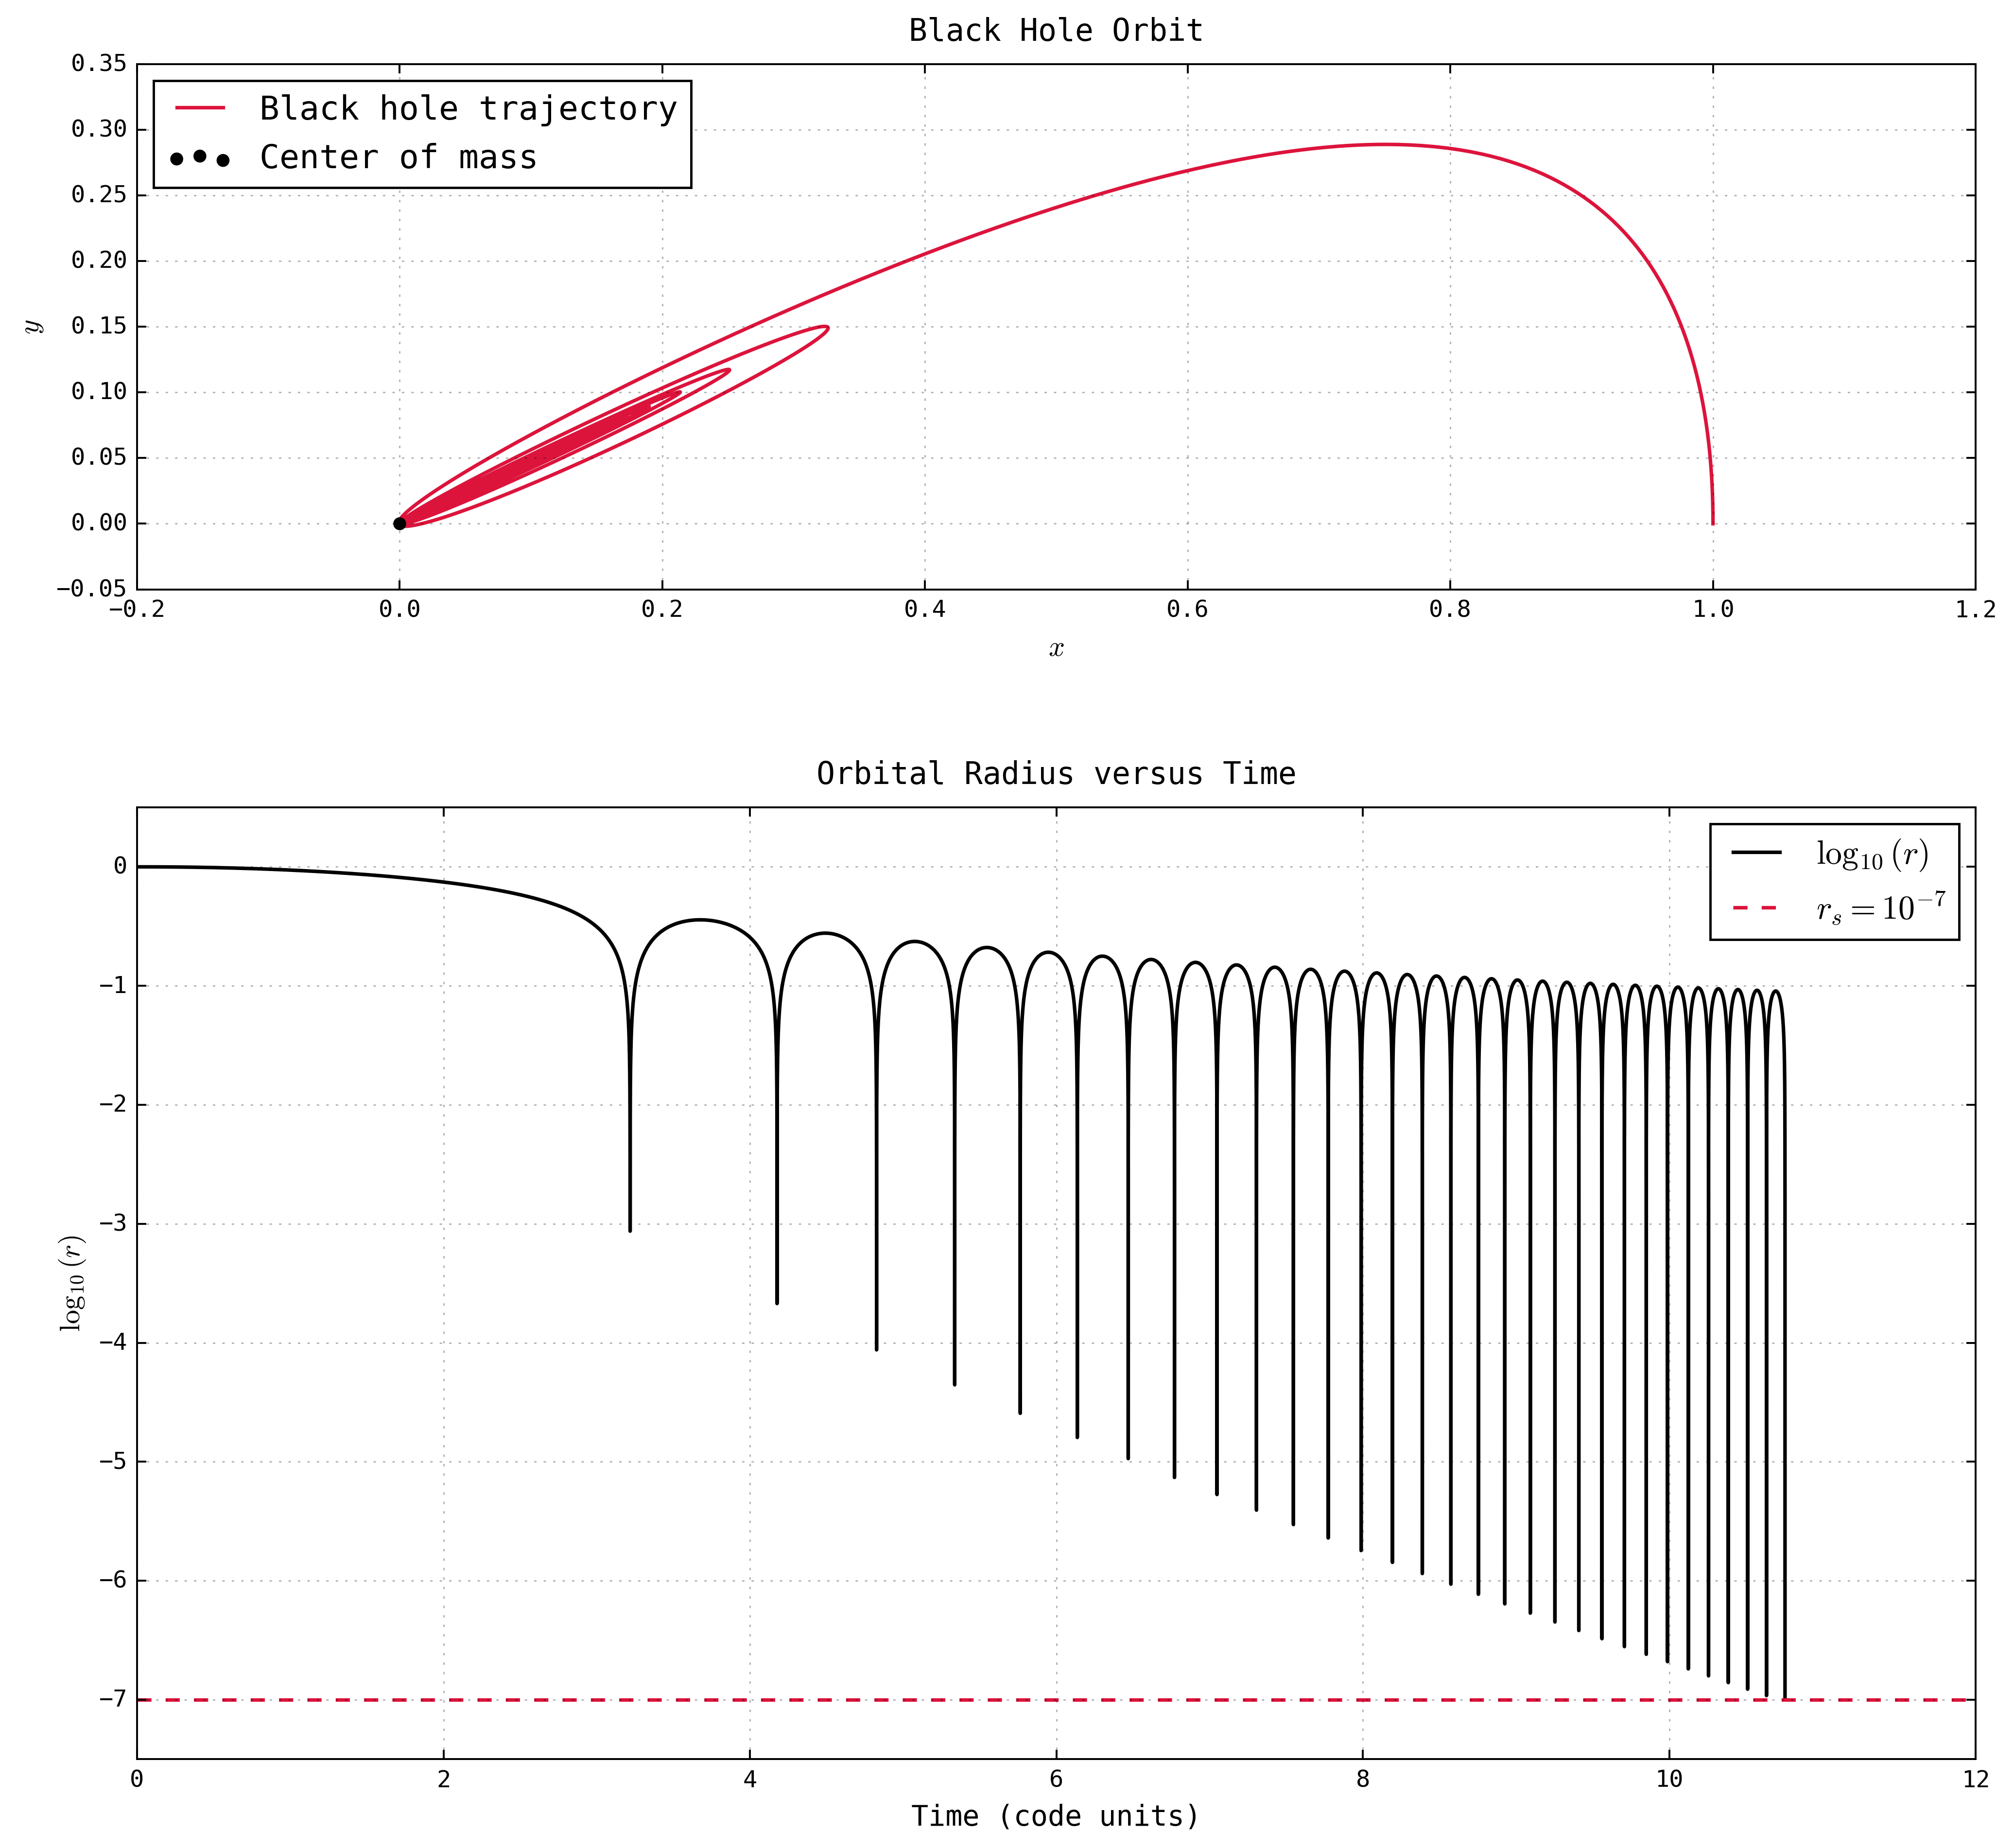

In [117]:
# (b) 

A = 1
B = 1
r_s = 1e-7
delta = 1e-10
r0 = 1.0
v_circ = np.sqrt(1/(4*r0))
state_b = np.array([r0, 0.0, 0.0, 0.8*v_circ])

times_b, states_b = adaptive_rk4(state_b, A=A, B=B, delta=delta, t_end=150, r_stop=r_s)
x_b, y_b, vx_b, vy_b = states_b.T
r_b = np.sqrt(x_b**2 + y_b**2)
reached = r_b[-1] <= r_s*(1 + 1e-8)
print(f"Reached Schwarzschild radius: {reached}")
print(f"Final radius = {r_b[-1]:.3e}")
print(f"Final time = {times_b[-1]:.6f} code units")
print(f"Number of steps = {len(times_b)-1}")

fig, ax = plt.subplots(2, 1, figsize=(12, 12), dpi=350)
ax[0].plot(x_b, y_b, color="crimson", linewidth=1.5, label="Black hole trajectory")
ax[0].scatter(0, 0, color="black", s=20, zorder=3, label="Center of mass")
ax[0].set_aspect("equal", adjustable="box")
ax[0].set_xlabel(r"$x$", fontsize=12)
ax[0].set_ylabel(r"$y$", fontsize=12)
ax[0].set_title("Black Hole Orbit", fontsize=13, pad=10)
ax[0].legend(loc="best", fontsize=14, frameon=True)

ax[1].plot(times_b, np.log10(r_b), color="black", linewidth=1.5, label=r"$\log_{10}(r)$")
ax[1].axhline(np.log10(r_s), color="crimson", linestyle="--", linewidth=1.5, label=r"$r_s=10^{-7}$")
ax[1].set_xlabel("Time (code units)", fontsize=12)
ax[1].set_ylabel(r"$\log_{10}(r)$", fontsize=12)
ax[1].set_title("Orbital Radius versus Time", fontsize=13, pad=10)
ax[1].set_ylim(-7.5, 0.5)
ax[1].legend(loc="best", fontsize=14, frameon=True)

for axis in ax:
    axis.tick_params(axis="both", direction="in", top=True, right=True, labelsize=10, width=0.8, length=4)
    axis.tick_params(which="minor", direction="in", top=True, right=True, width=0.6, length=2)
    axis.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.3)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)

plt.tight_layout()
plt.savefig(figures_dir /"bh_part_b.png", dpi=350, bbox_inches="tight")
plt.show()

One code time unit = 1.4586 Myr

A=0.50, B=0.50, B/A=1.00: 16.7918 Myr
A=0.50, B=1.06, B/A=2.11: 37.4251 Myr
A=0.50, B=2.24, B/A=4.47: Not resolved
A=0.50, B=4.73, B/A=9.46: Not resolved
A=0.50, B=10.00, B/A=20.00: Not resolved
A=1.06, B=0.50, B/A=0.47: 5.9918 Myr
A=1.06, B=1.06, B/A=1.00: 15.6632 Myr
A=1.06, B=2.24, B/A=2.11: 35.2947 Myr
A=1.06, B=4.73, B/A=4.47: Not resolved
A=1.06, B=10.00, B/A=9.46: Not resolved
A=2.24, B=0.50, B/A=0.22: 9.8644 Myr
A=2.24, B=1.06, B/A=0.47: 6.0300 Myr
A=2.24, B=2.24, B/A=1.00: 14.6672 Myr
A=2.24, B=4.73, B/A=2.11: Not resolved
A=2.24, B=10.00, B/A=4.47: Not resolved
A=4.73, B=0.50, B/A=0.11: 19.0637 Myr
A=4.73, B=1.06, B/A=0.22: 9.9022 Myr
A=4.73, B=2.24, B/A=0.47: 6.0515 Myr
A=4.73, B=4.73, B/A=1.00: 13.9864 Myr
A=4.73, B=10.00, B/A=2.11: Not resolved
A=10.00, B=0.50, B/A=0.05: 39.2585 Myr
A=10.00, B=1.06, B/A=0.11: 19.0966 Myr
A=10.00, B=2.24, B/A=0.22: 9.9235 Myr
A=10.00, B=4.73, B/A=0.47: 6.0632 Myr
A=10.00, B=10.00, B/A=1.00: 13.4147 Myr


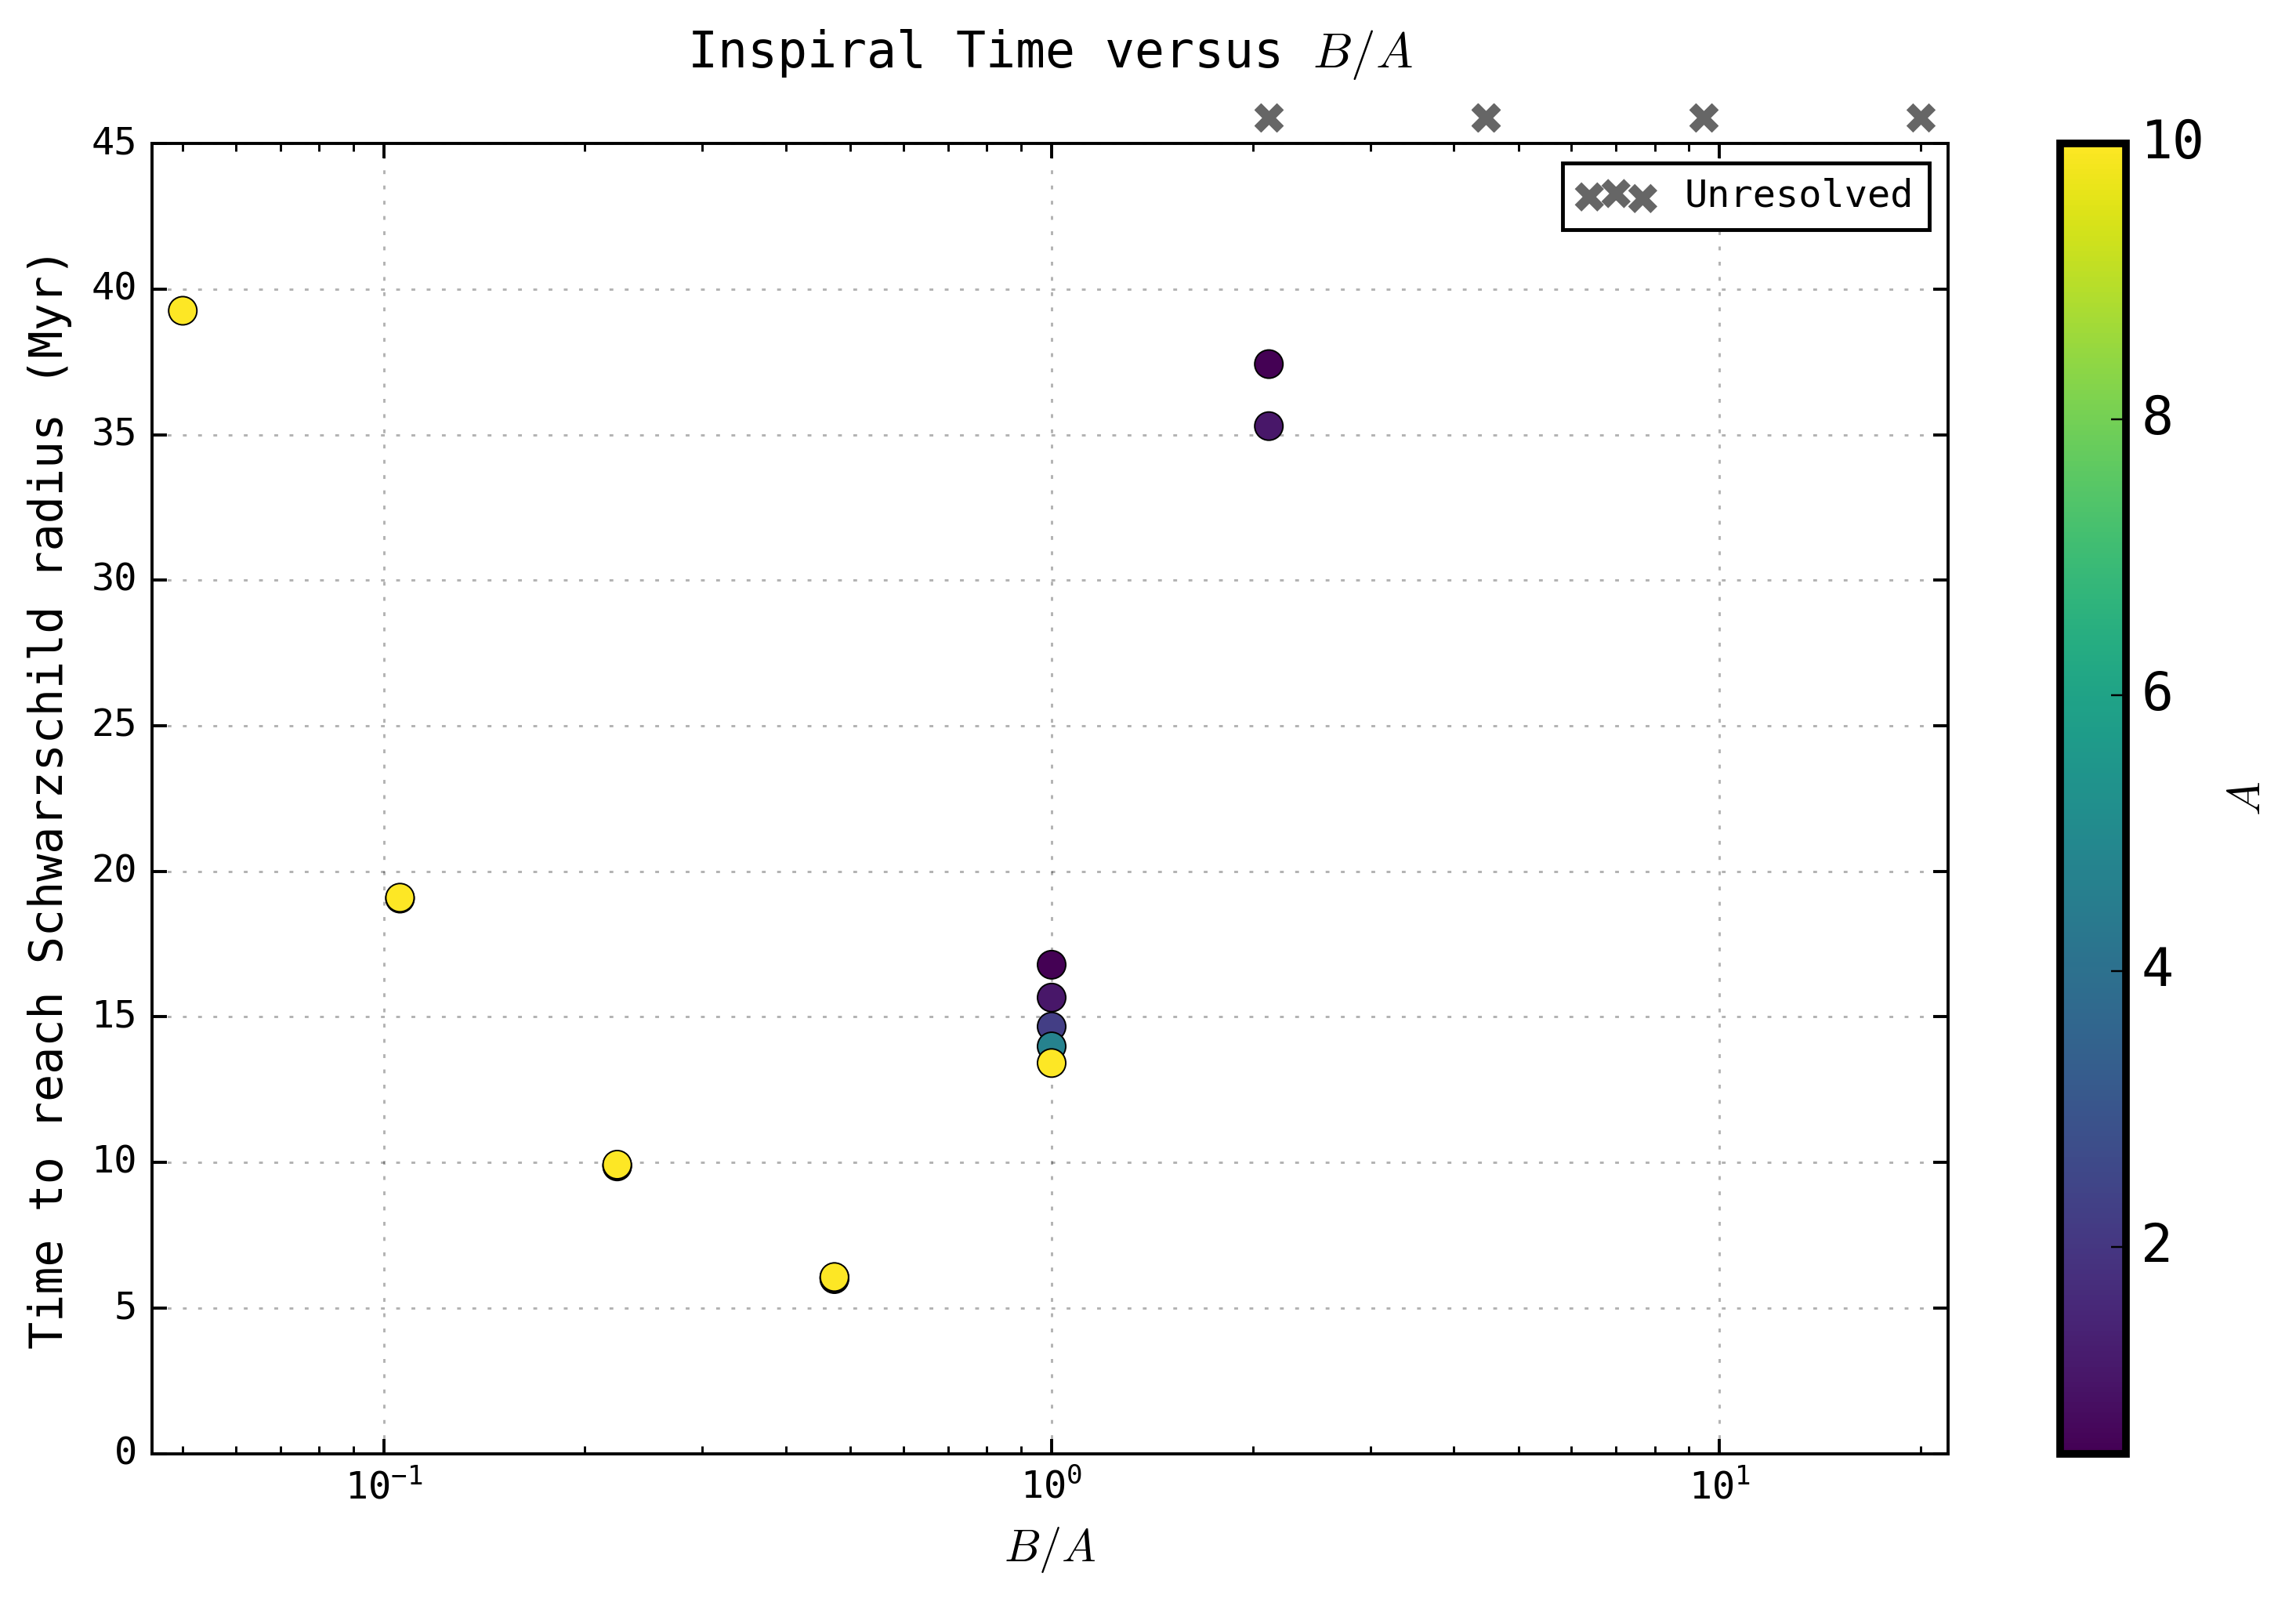

In [118]:

# (c) 

# numerical time to Myr
pc = 3.085677581491367e16
G_si = 6.67430e-11
c = 299792458.0
Myr = 1e6 * 365.25 * 24 * 3600
length_unit = 100 * pc
M_bh = r_s * length_unit * c**2 / (2*G_si)
time_unit_Myr = np.sqrt(length_unit**3 / (G_si*M_bh)) / Myr
print(f"One code time unit = {time_unit_Myr:.4f} Myr\n")
A_values = np.geomspace(0.5, 10, 5)
B_values = np.geomspace(0.5, 10, 5)
ratios = []
inspiral_times = []
A_plot = []
unresolved_ratios = []

for A in A_values:
    for B in B_values:
        try:
            times_c, states_c = adaptive_rk4(state_b, A=float(A), B=float(B), delta=delta, t_end=150, r_stop=r_s, max_steps=1000000)
            r_final = np.hypot(states_c[-1, 0], states_c[-1, 1])
            reached = r_final <= r_s*(1 + 1e-8)
        except RuntimeError:
            reached = False
        if reached:
            t_Myr = times_c[-1] * time_unit_Myr
            ratios.append(B/A)
            inspiral_times.append(t_Myr)
            A_plot.append(A)
            print(f"A={A:.2f}, B={B:.2f}, B/A={B/A:.2f}: {t_Myr:.4f} Myr")

        else:
            unresolved_ratios.append(B/A)
            print(f"A={A:.2f}, B={B:.2f}, B/A={B/A:.2f}: "
                  "Not resolved")


fig, ax = plt.subplots(figsize=(9, 6), dpi=350)

sc = ax.scatter(ratios, inspiral_times, c= A_plot, cmap="viridis", s=55, edgecolor="black", linewidth=0.4, zorder=3)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(r"$A$", fontsize=12)

# unresolved cases at the top edge (not physical times)
if unresolved_ratios:
    ax.scatter(unresolved_ratios, np.full(len(unresolved_ratios), 1.02), transform=ax.get_xaxis_transform(), color="0.4", marker="x", s=35, clip_on=False, label="Unresolved")
    ax.legend(loc="best", fontsize=10, frameon=True)
ax.set_xscale("log")
ax.set_xlim(0.045, 22)
ax.set_xlabel(r"$B/A$", fontsize=12)
ax.set_ylabel("Time to reach Schwarzschild radius (Myr)", fontsize=12)
ax.set_title(r"Inspiral Time versus $B/A$", fontsize=13, pad=20)

ax.tick_params(axis="both", direction="in", top=True, right=True, labelsize=10, width=0.8, length=4)
ax.tick_params(which="minor", direction="in", top=True, right=True, width=0.6, length=2)
ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.3)

for spine in ax.spines.values():
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.savefig(figures_dir/"bh_part_c.png", dpi=350, bbox_inches="tight")
plt.show()


v0/v_circ = 0.60: 14.9536 Myr
v0/v_circ = 0.70: 15.4057 Myr
v0/v_circ = 0.80: 15.6884 Myr
v0/v_circ = 0.90: 15.9881 Myr
v0/v_circ = 0.95: 16.0604 Myr
A=0.5, B=0.5, B/A=1.0: 16.7918 Myr
A=1.0, B=1.0, B/A=1.0: 15.6884 Myr
A=2.0, B=2.0, B/A=1.0: 14.7925 Myr
A=5.0, B=5.0, B/A=1.0: 13.8992 Myr
A=10.0, B=10.0, B/A=1.0: 13.4147 Myr


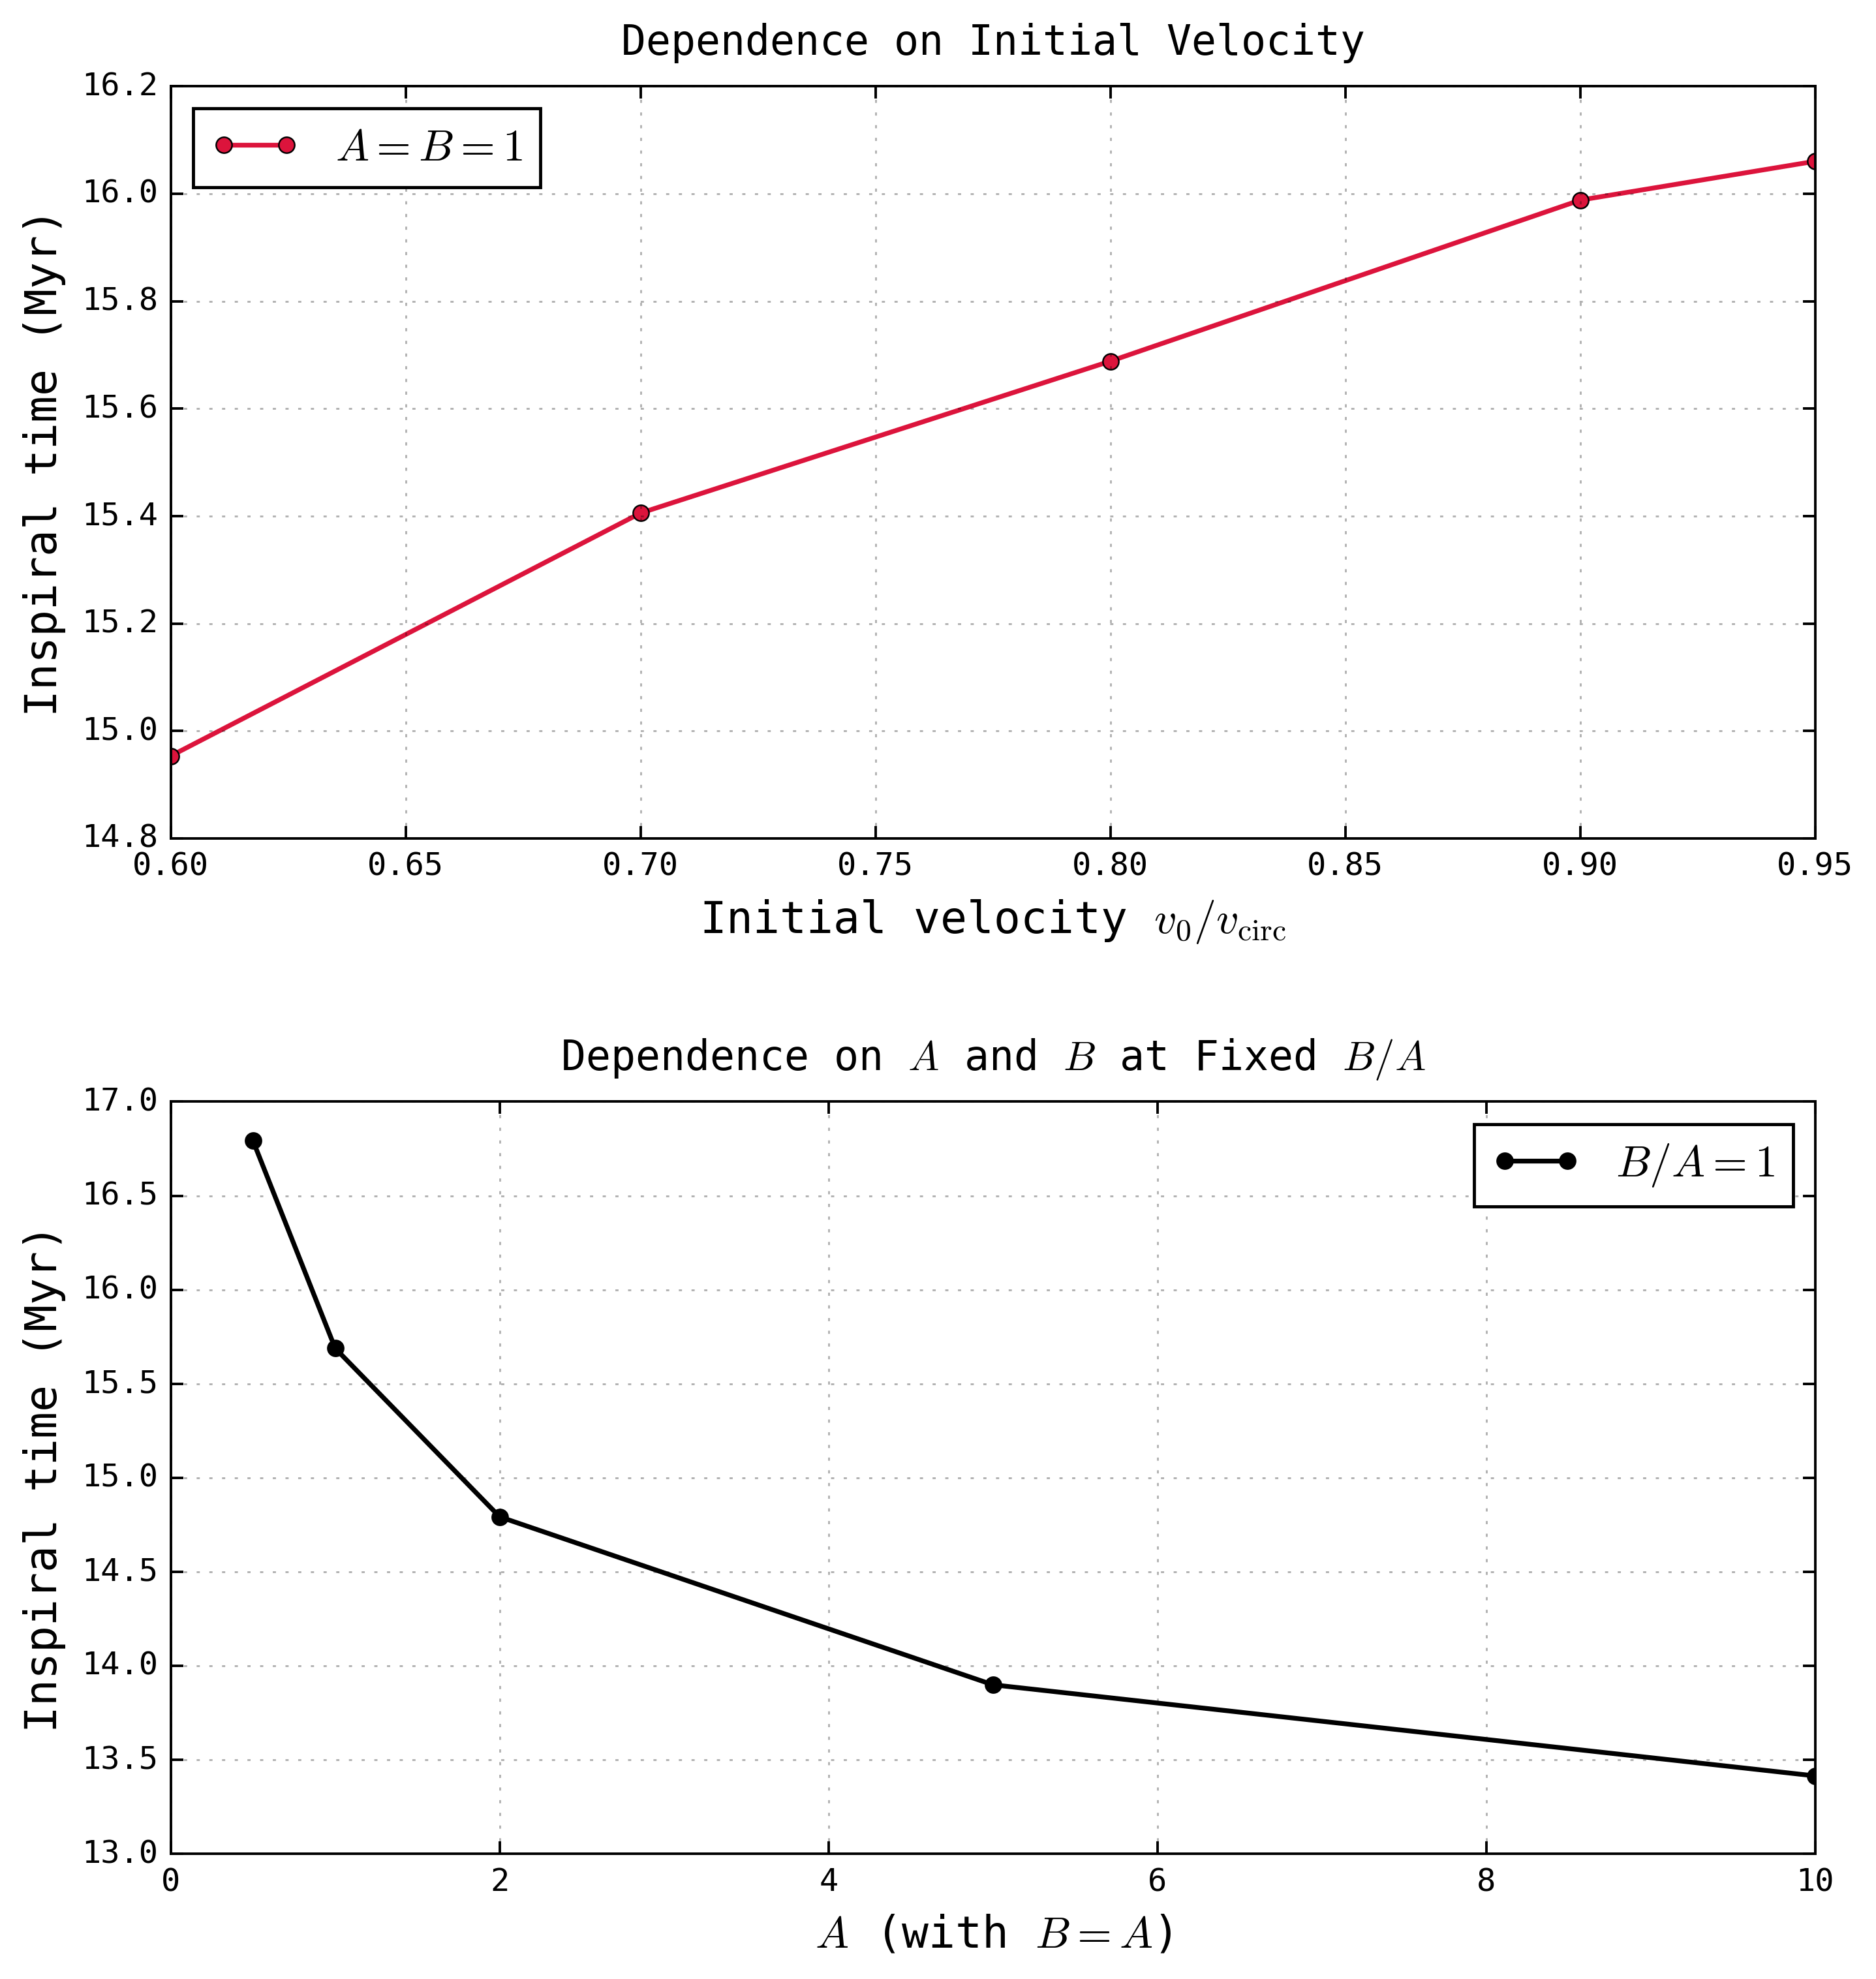

In [119]:

# (d) 

delta = 1e-10
velocity_fracs = np.array([0.6, 0.7, 0.8, 0.9, 0.95])
velocity_times = []

for fraction in velocity_fracs:
    initial_state = np.array([1.0, 0.0, 0.0, fraction*v_circ])
    try:
        times_d, states_d = adaptive_rk4(initial_state, A=1, B=1, delta=delta, t_end=150, r_stop=r_s)
        r_final = np.hypot(states_d[-1, 0], states_d[-1, 1])
        reached = r_final <= r_s*(1 + 1e-8)
        t_Myr = times_d[-1]*time_unit_Myr if reached else np.nan
    except RuntimeError:
        t_Myr = np.nan
    velocity_times.append(t_Myr)
    print(f"v0/v_circ = {fraction:.2f}: {t_Myr:.4f} Myr")

pairs = [(0.5, 0.5), (1, 1), (2, 2), (5, 5), (10, 10)]
pair_times = []

for A, B in pairs:
    try:
        times_d, states_d = adaptive_rk4(state_b, A=A, B=B, delta=delta, t_end=150, r_stop=r_s)
        r_final = np.hypot(states_d[-1, 0], states_d[-1, 1])
        reached = r_final <= r_s*(1 + 1e-8)
        t_Myr = times_d[-1]*time_unit_Myr if reached else np.nan
    except RuntimeError:
        t_Myr = np.nan
    pair_times.append(t_Myr)
    print(f"A={A:.1f}, B={B:.1f}, B/A={B/A:.1f}: {t_Myr:.4f} Myr")

fig, ax = plt.subplots(2, 1, figsize=(9, 9), dpi=350, gridspec_kw={"hspace": 0.35})
ax[0].plot(velocity_fracs, velocity_times, "o-", color="crimson", linewidth=1.5, markersize=5, label=r"$A=B=1$")
ax[0].set_xlabel(r"Initial velocity $v_0/v_{\mathrm{circ}}$", fontsize=14)
ax[0].set_ylabel("Inspiral time (Myr)", fontsize=14)
ax[0].set_title("Dependence on Initial Velocity", fontsize=13, pad=10)
ax[0].legend(loc="best", fontsize=14, frameon=True)

ax[1].plot([A for A, B in pairs], pair_times, "o-", color="black", linewidth=1.5, markersize=5, label=r"$B/A=1$")
ax[1].set_xlabel(r"$A$ (with $B=A$)", fontsize=14)
ax[1].set_ylabel("Inspiral time (Myr)", fontsize=14)
ax[1].set_title(r"Dependence on $A$ and $B$ at Fixed $B/A$", fontsize=13, pad=10)
ax[1].legend(loc="best", fontsize=14, frameon=True)

for axis in ax:
    axis.tick_params(axis="both", direction="in", top=True, right=True, labelsize=10, width=0.8, length=4)
    axis.tick_params(which="minor", direction="in", top=True, right=True, width=0.6, length=2)
    axis.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.3)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)

plt.subplots_adjust(left=0.15, right=0.95, top=0.95, bottom=0.09)
plt.savefig(figures_dir / "bh_part_d.png", dpi=350, bbox_inches="tight")
plt.show()